# 건물 속성 빈칸 추정: 연면적 · 사용승인 연대 · 지상층수 (Keras Dense)

사창동 건물 2,448동 중 건축물대장 속성이 비어 있는 건물이 있다. 법안 기준에 **연면적**이나 **사용승인일**이 들어가면 이 건물들은 지도에서 늘 **판정불가**로 남는다 (판정 시범의 판정불가 이유 "속성 없음(연면적)" 등).
그래서 추정 대상을 판정불가의 원인에 맞춘다. 모든 건물에 있는 정보(바닥 모양, 위치, 주변 건물)만으로 **연면적 구간**, **사용승인 연대**, **지상층수 구간**을 각각 추정하는 신경망을 만든다.

추정값은 화면에서 **참고용**으로만 보여 주고, 법안 판정에는 쓰지 않는다 (판정은 건축물대장 실제 값만 사용).

**값 출처 순서**: ① 브이월드 건물통합정보 값 → ② 건축물대장 표제부(`data/bldg_register_사창동.csv`, `collect/collect_register.py` 로 받음. 필지에 표제부 한 줄·건물 한 동이면 대장 값 우선) → ③ 그래도 빈 건물만 신경망 추정 (참고용).

**순서**: 1 문제 → 2 데이터 → 3 전처리 (특징 만들기) → 4 학습/테스트 분리 → 5 기준선 → 6 신경망 → 7 과적합 확인 → 8 은닉층 실험 → 9 오답 분석 → 10 결과표 → 11 화면에 쓰이는 곳

## 0. 준비 (Colab 한글 글꼴 설치)

In [1]:
import os, re, sys
if 'google.colab' in sys.modules and not os.path.exists('/usr/share/fonts/truetype/nanum'):
    !apt-get -qq install fonts-nanum > /dev/null

In [2]:
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
import json, base64, urllib.request, urllib.parse
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from IPython.display import Markdown, display

import matplotlib.font_manager as fm
_f = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'
if os.path.exists(_f):
    fm.fontManager.addfont(_f)                       # 세션 다시 시작 없이 한글 글꼴 등록
    plt.rcParams['font.family'] = fm.FontProperties(fname=_f).get_name()
plt.rcParams['axes.unicode_minus'] = False

SEED = 42
np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()   # 다시 실행해도 같은 결과

I0000 00:00:1795393757.024908    2518 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1795393758.075082    2518 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 1. 문제
- **추정 대상 3개** (판정불가의 원인이 되는 속성): 연면적 구간 4개, 사용승인 연대 4개, 지상층수 구간 5개. 대상마다 따로 softmax 확률을 낸다.
- **학습 데이터**: 그 속성이 있는 건물. **추정 대상**: 그 속성이 빈 건물. "빈 값"은 판정(`web/judge.js`, `collect/build_web_data.py`)과 같은 기준이다 (없음, 빈 글자, 0).
- **입력**: 건물마다 반드시 있는 것만 쓴다. 바닥 도형(면적·둘레·모양), 위치, 그리고 **그 속성이 있는 주변 건물**의 층수·연면적·사용승인 연도. 세 모델이 같은 특징 17개를 쓴다.
- **모델을 대상마다 따로 두는 이유**: 대상마다 학습할 수 있는 건물(값이 있는 건물)이 조금씩 다르다. 몸통 하나에 출력 3개를 다는 구조는 세 값이 모두 있는 건물만 쓰거나 손실을 가려야 해서 복잡해진다. 같은 구조(Dense 64-32)를 셋으로 두면 설명과 비교가 쉽다.
- 건물명 등 이름 필드는 쓰지 않는다. 출처가 불명인 `cheongju_buildings_footprint.geojson` 도 쓰지 않는다.
- 추정 대상 건물에 없는 건축물대장 속성(용도·높이·구조 등)은 입력으로 쓰지 않는다.

## 2. 데이터
브이월드 건물 도형 + 건축물대장 속성 `data/bldginfo_사창동.geojson`. GitHub 저장소 main 에서 읽고, 안 되면 저장소의 `data/` 를 읽는다.
웹 지도(`collect/build_web_data.py`)는 이 파일의 건물을 **순서 그대로 전부(2,448동)** 쓰므로, 건물을 가리키는 열쇠는 파일 안 순서(`idx`)다. PNU 는 한 필지에 건물이 여럿이면 겹치므로 열쇠로 쓸 수 없다.

In [3]:
NAME = 'bldginfo_사창동.geojson'
URL = 'https://raw.githubusercontent.com/cbnu-lawmap/law-impact-map/main/data/' + urllib.parse.quote(NAME)

def load_geojson():
    try:
        with urllib.request.urlopen(URL, timeout=60) as r:
            return json.loads(r.read().decode('utf-8'))
    except Exception as e:
        print('GitHub 에서 읽지 못함:', type(e).__name__)
    for d in [os.environ.get('NB_LOCAL_DATA'), '../data', '.']:
        if d and os.path.exists(os.path.join(d, NAME)):
            with open(os.path.join(d, NAME), encoding='utf-8') as f:
                return json.load(f)
    from google.colab import files
    print(NAME, '파일을 올려 주세요'); files.upload()
    with open(NAME, encoding='utf-8') as f:
        return json.load(f)

gj = load_geojson()
feats = gj['features']
# 쓰는 속성만 꺼낸다 (이름 필드는 꺼내지 않음)
ATTRS = ['usability', 'totalarea', 'grnd_flr', 'useapr_day']
B = pd.DataFrame([{k: f['properties'].get(k) for k in ['pnu'] + ATTRS} for f in feats]).astype(object)
B['pnu'] = B['pnu'].astype(str)
B['idx'] = range(len(B))

def empty(v):            # build_web_data.py / web/judge.js 의 '빈 값'과 같은 기준 (None, '', 0)
    return v is None or v == '' or v == 0 or (isinstance(v, float) and np.isnan(v))

print('전체', len(B), '동')

전체 2448 동


### 2-1. 값 출처: 건축물대장 표제부를 먼저 쓴다
건축물대장 표제부(공공데이터포털 건축HUB, `collect/collect_register.py` 가 받음)는 `data/bldg_register_사창동.csv` 에 있다. 열은 `pnu` 와 `totalarea`(연면적)·`useapr_day`(사용승인일)·`grnd_flr`(지상층수)·`hhld_cnt`(세대수)·`main_purps_cd`(주용도 코드). API 이름(`totArea`, `useAprDay`, `grndFlrCnt`, `hhldCnt`, `mainPurpsCd`)도 받는다.

규칙 (`collect/build_web_data.py` 와 같음, 판정은 대장 값 우선):
- 표제부는 필지(PNU) 단위라, **그 PNU 에 표제부 한 줄, 지도 건물도 한 동**일 때만 맞춘다. 한 필지에 건물이 여럿이거나 표제부가 여러 줄이면 어느 건물 값인지 알 수 없어 쓰지 않는다.
- 맞춘 건물은 표제부에 값이 있는 속성을 **표제부 값으로 바꾼다** (브이월드 빈 칸 채우기와 다른 값 바꾸기 모두). 표제부가 비었거나 0 이면 브이월드 값을 둔다.
- 대장 값은 판정에도 쓰인다. 신경망 추정은 **표제부를 반영한 뒤에도 빈 건물에만** 한다. 학습 정답도 표제부를 반영한 값이다.

파일이 없으면 아무것도 바뀌지 않는다. 세대수는 아직 판정 규칙에 없어 읽기만 한다.

In [4]:
REG_NAME = 'bldg_register_사창동.csv'
REG_COLS = {'totalarea': ['totalarea', 'totArea'], 'useapr_day': ['useapr_day', 'useAprDay'],
            'grnd_flr': ['grnd_flr', 'grndFlrCnt'], 'usability': ['main_purps_cd', 'mainPurpsCd']}

def load_register():
    # 저장소에 넣은 파일을 먼저 본다 (브랜치에서 실행할 때도 그 브랜치 파일을 쓰도록)
    for d in [os.environ.get('NB_LOCAL_DATA'), '../data', '.']:
        if d and os.path.exists(os.path.join(d, REG_NAME)):
            return pd.read_csv(os.path.join(d, REG_NAME), dtype=str, encoding='utf-8-sig')
    try:
        return pd.read_csv('https://raw.githubusercontent.com/cbnu-lawmap/law-impact-map/main/data/' + urllib.parse.quote(REG_NAME),
                           dtype=str, encoding='utf-8-sig')
    except Exception:
        return None

def reg_value(attr, v):
    # 비었거나 0, 형식이 맞지 않으면 None (그 속성은 브이월드 값을 둔다)
    if v is None or (isinstance(v, float) and np.isnan(v)) or str(v).strip() == '':
        return None
    v = str(v).strip()
    try:
        if attr == 'totalarea': return float(v) or None
        if attr == 'grnd_flr': return int(float(v)) or None
    except ValueError:
        return None
    if attr == 'useapr_day':
        v = v.replace('-', '')[:8]
        return v if re.fullmatch(r'(19|20)\d{6}', v) else None
    if attr == 'usability':
        return v if re.fullmatch(r'\d{5}', v) else None
    return v

for a in ATTRS:
    B['src_' + a] = np.where(B[a].map(empty), '', '브이월드')

REG = load_register()
REG_FILLED = {a: 0 for a in ATTRS}     # 브이월드 빈 칸을 표제부로 채움
REG_REPLACED = {a: 0 for a in ATTRS}   # 브이월드 값을 다른 표제부 값으로 바꿈
if REG is None:
    print('건축물대장 표제부 파일 없음: 브이월드 값만 쓴다 (추정 대상은 브이월드에서 빈 건물 전부)')
else:
    REG['pnu'] = REG['pnu'].astype(str).str.strip()
    one = REG[REG['pnu'].map(REG['pnu'].value_counts()) == 1].set_index('pnu')
    single = B['pnu'].map(B['pnu'].value_counts()) == 1
    matched = B.index[single & B['pnu'].isin(one.index)]
    for i in matched:
        r = one.loc[B.at[i, 'pnu']]
        for a in ATTRS:
            col = next((c for c in REG_COLS[a] if c in one.columns), None)
            v = reg_value(a, r[col]) if col else None
            if empty(v) or B.at[i, a] == v:
                continue
            (REG_FILLED if empty(B.at[i, a]) else REG_REPLACED)[a] += 1
            B.at[i, a] = v; B.at[i, 'src_' + a] = '건축물대장'
    print('건축물대장 표제부', len(REG), '줄 (PNU 하나에 한 줄인 것', len(one), '), 맞춘 건물', len(matched), '동')
    print('표제부로 채운 빈 칸:', REG_FILLED)
    print('표제부 값으로 바꾼 칸:', REG_REPLACED)

### 2-2. 판정불가는 어떤 속성이 비어서 생기나

In [5]:
ATTR_NAMES = {'usability': '용도', 'totalarea': '연면적', 'grnd_flr': '지상층수', 'useapr_day': '사용승인일'}
E = pd.DataFrame({n: B[a].map(empty) for a, n in ATTR_NAMES.items()})
combo = E.apply(lambda r: ' + '.join(c for c in E.columns if r[c]) or '(빈 값 없음)', axis=1).value_counts()
display(E.sum().to_frame('빈 건물 수').T)
display(combo.to_frame('동수'))
all4 = int(E.all(axis=1).sum())
display(Markdown(
    f"연면적이 빈 건물 **{int(E['연면적'].sum())}동**, 사용승인일이 빈 건물 **{int(E['사용승인일'].sum())}동**, "
    f"지상층수가 빈 건물 **{int(E['지상층수'].sum())}동**이다. 이 중 {all4}동은 네 속성이 모두 비어 있다 (건축물대장과 연결되지 않은 건물). "
    f"법안 기준에 연면적이나 사용승인일이 있으면 이 건물들이 판정불가가 되므로, 이 두 속성과 지상층수를 추정 대상으로 삼는다. "
    f"용도는 이름 같은 범주라 모양과 위치만으로 맞히기 어렵고 판정에서 가장 먼저 걸러지는 조건이라 이번에는 추정하지 않는다."))

,용도,연면적,지상층수,사용승인일
빈 건물 수,337,336,340,330


,동수
(빈 값 없음),2100
용도 + 연면적 + 지상층수 + 사용승인일,314
용도 + 연면적 + 지상층수,17
사용승인일,6
용도 + 지상층수 + 사용승인일,5
연면적 + 지상층수 + 사용승인일,3
용도 + 연면적 + 사용승인일,1
지상층수,1
연면적 + 사용승인일,1


연면적이 빈 건물 **336동**, 사용승인일이 빈 건물 **330동**, 지상층수가 빈 건물 **340동**이다. 이 중 314동은 네 속성이 모두 비어 있다 (건축물대장과 연결되지 않은 건물). 법안 기준에 연면적이나 사용승인일이 있으면 이 건물들이 판정불가가 되므로, 이 두 속성과 지상층수를 추정 대상으로 삼는다. 용도는 이름 같은 범주라 모양과 위치만으로 맞히기 어렵고 판정에서 가장 먼저 걸러지는 조건이라 이번에는 추정하지 않는다.

## 3. 전처리 (특징 만들기)
### 3-1. 추정 대상 3개와 구간
**연면적 (4구간: 200㎡ 미만 / 200~500㎡ / 500~1,000㎡ / 1,000㎡ 이상)**. 법은 연면적을 "몇 ㎡ 이상·미만"으로 자르므로, 숫자를 맞히는 회귀보다 경계 기준으로 나눈 구간과 그 확률을 보여 주는 편이 화면에서 읽기 쉽다.
- 200㎡: 판정 시범의 "연면적 200㎡ 미만·2층 이하 소규모 건축물" 기준.
- 500㎡: 건축법 시행령 별표 1에서 제2종 근린생활시설(공연장·종교집회장·제조업소 등)과 다른 용도를 가르는 "500㎡ 미만" 기준이 많다.
- 1,000㎡: 판정 시범의 "연면적 1천㎡ 이상 공동주택", 별표 1의 제1종 근린생활시설 "1천㎡ 미만" 기준.
- 1,000㎡ 이상은 하나로 묶는다. 그 위(3천·5천·1만㎡)로 더 나누면 구간마다 학습 건물이 몇십 동뿐이라 (아래 표) 테스트에서 몇 동으로 정확도를 재게 된다. 빈 건물은 대부분 작은 건물이라 위쪽을 잘게 나눌 필요도 적다.
- 85㎡(주거용 85㎡ 이하) 기준은 200㎡ 미만 구간 안에 들어간다. 따로 나누지 않으므로 이 기준에는 추정이 도움이 되지 않는다.

**사용승인 연대 (4구간: 1989년 이전 / 1990년대 / 2000년대 / 2010년 이후)**. 사창동은 1980년대 건물이 가장 많아 1989년 이전을 하나로 묶고, 그 뒤는 10년 단위로 나눈다. 법안의 "사용승인 후 N년" 기준은 날짜 경계라 연대와 정확히 맞지 않으므로, 연대 추정은 "대략 언제 지었나"를 보는 참고용이다.

**지상층수 (5구간: 1층 / 2층 / 3층 / 4~5층 / 6층 이상)**. 2층에 몰려 있고 6층 이상은 드물다. 4층과 5층은 합쳐도 3층과 비슷한 크기, 6층 이상은 아파트 등 고층을 한데 묶는다.

In [6]:
def area_class(v):
    v = float(v)
    return 0 if v < 200 else 1 if v < 500 else 2 if v < 1000 else 3

def year_of(v):
    s = str(v)[:4]
    return int(s) if s.isdigit() and 1900 <= int(s) <= 2030 else None

def year_class(v):
    y = year_of(v)
    return None if y is None else 0 if y <= 1989 else 1 if y <= 1999 else 2 if y <= 2009 else 3

def flr_class(v):
    n = int(float(v))
    return 0 if n <= 1 else 1 if n == 2 else 2 if n == 3 else 3 if n <= 5 else 4

TARGETS = {
    'area': {'name': '연면적', 'attr': 'totalarea', 'cls': area_class,
             'labels': ['200㎡ 미만', '200~500㎡', '500~1,000㎡', '1,000㎡ 이상']},
    'year': {'name': '사용승인 연대', 'attr': 'useapr_day', 'cls': year_class,
             'labels': ['1989년 이전', '1990년대', '2000년대', '2010년 이후']},
    'flr':  {'name': '지상층수', 'attr': 'grnd_flr', 'cls': flr_class,
             'labels': ['1층', '2층', '3층', '4~5층', '6층 이상']},
}
for t, T in TARGETS.items():
    B['miss_' + t] = B[T['attr']].map(empty)              # 판정과 같은 '빈 값' → 추정 대상
    y = [-1 if m else T['cls'](v) for v, m in zip(B[T['attr']], B['miss_' + t])]
    B['y_' + t] = [-1 if c is None else c for c in y]     # 값은 있는데 읽을 수 없으면 학습·추정 모두에서 뺌
    bad = int(((B['y_' + t] < 0) & ~B['miss_' + t]).sum())
    print(f"{T['name']}: 값 있음 {int((B['y_' + t] >= 0).sum())}동 / 빈 값 {int(B['miss_' + t].sum())}동" + (f' / 값을 읽을 수 없음 {bad}동' if bad else ''))
B['year'] = [year_of(v) if not empty(v) else np.nan for v in B['useapr_day']]
B['year'] = B['year'].astype(float)

big = pd.to_numeric(B['totalarea'], errors='coerce')
print('1,000㎡ 이상을 더 나누면: 1천~3천', int(((big >= 1000) & (big < 3000)).sum()), '동, 3천~5천', int(((big >= 3000) & (big < 5000)).sum()),
      '동, 5천~1만', int(((big >= 5000) & (big < 10000)).sum()), '동, 1만 이상', int((big >= 10000).sum()), '동')
pd.concat({T['name']: pd.Series(np.array(T['labels'])[B.loc[B['y_' + t] >= 0, 'y_' + t]]).value_counts().reindex(T['labels'])
           for t, T in TARGETS.items()}).to_frame('동수 (값 있는 건물)')

연면적: 값 있음 2112동 / 빈 값 336동
사용승인 연대: 값 있음 2118동 / 빈 값 330동
지상층수: 값 있음 2108동 / 빈 값 340동
1,000㎡ 이상을 더 나누면: 1천~3천 106 동, 3천~5천 17 동, 5천~1만 13 동, 1만 이상 11 동


동수 (값 있는 건물)
연면적     200㎡ 미만              935
        200~500㎡             687
        500~1,000㎡           343
        1,000㎡ 이상            147
사용승인 연대 1989년 이전            1076
        1990년대               392
        2000년대               355
        2010년 이후             295
지상층수    1층                   272
        2층                   849
        3층                   433
        4~5층                 510
        6층 이상                 44

### 3-2. 바닥 도형
경위도를 사창동 중심 기준 미터 좌표로 바꾼다 (동 하나 크기에서는 등장방형 투영으로 충분: 동서 1도 = 111.32km × cos(위도)).
- `area` 바닥면적(㎡, 구멍 뺌), `log_area`, `perim` 둘레(m)
- `compact` 원에 가까운 정도 4πA/P² (원 = 1, 길쭉하거나 복잡할수록 작음)
- `n_vert` 꼭짓점 수, `elong` 가장 긴 방향 / 짧은 방향 길이 비 (꼭짓점 주성분)
- `cx`, `cy` 중심점 위치(m, 동 중심 기준)

In [7]:
allpts = np.array([pt for f in feats for poly in f['geometry']['coordinates'] for ring in poly for pt in ring])
LON0, LAT0 = allpts[:, 0].mean(), allpts[:, 1].mean()
KX = 111320.0 * np.cos(np.radians(LAT0)); KY = 110540.0

def to_m(ring):
    a = np.asarray(ring, dtype=float)
    return np.c_[(a[:, 0] - LON0) * KX, (a[:, 1] - LAT0) * KY]

def ring_area(r):         # 신발끈 공식 (부호 없음)
    x, y = r[:, 0], r[:, 1]
    return 0.5 * abs(np.dot(x, np.roll(y, -1)) - np.dot(y, np.roll(x, -1)))

def ring_perim(r):
    return np.sqrt(((r - np.roll(r, -1, axis=0)) ** 2).sum(1)).sum()

def shape_feats(geom):
    area = perim = 0.0; nv = 0; outer_pts = []
    for poly in geom['coordinates']:
        rings = [to_m(r) for r in poly]
        rings = [r[:-1] if len(r) > 1 and np.allclose(r[0], r[-1]) else r for r in rings]   # 닫는 점 제거
        area += ring_area(rings[0]) - sum(ring_area(h) for h in rings[1:])
        perim += sum(ring_perim(r) for r in rings)
        nv += len(rings[0]); outer_pts.append(rings[0])
    pts = np.vstack(outer_pts)
    c = pts.mean(0)
    ev = np.sort(np.linalg.eigvalsh(np.cov((pts - c).T)))
    elong = np.sqrt(ev[1] / max(ev[0], 1e-9))
    return dict(area=area, log_area=np.log1p(area), perim=perim, compact=4 * np.pi * area / perim ** 2,
                n_vert=nv, elong=min(elong, 50.0), cx=c[0], cy=c[1])

S_ = pd.DataFrame([shape_feats(f['geometry']) for f in feats])
B = pd.concat([B, S_], axis=1)
B[['area', 'perim', 'compact', 'n_vert', 'elong']].describe().round(2)

,area,perim,compact,n_vert,elong
count,2448.00,2448.00,2448.00,2448.00,2448.00
mean,148.98,49.22,0.68,8.64,1.65
std,165.67,27.47,0.09,5.68,1.01
min,0.00,0.02,0.05,3.00,1.00
25%,93.37,40.63,0.65,6.00,1.23
50%,117.56,46.03,0.71,8.00,1.42
75%,163.35,54.49,0.74,10.00,1.77
max,3604.86,690.01,0.83,115.00,33.23


### 3-3. 주변 건물 (이웃) 특징
가까운 건물은 좋은 단서다 (아파트 단지 옆은 아파트, 주택가 안은 주택). 이웃 특징은 **그 속성이 있는 다른 건물만**으로 만들고, **자기 자신은 반드시 뺀다**.

- `nb_flr_mean`, `nb_flr_med`, `nb_flr_max`: 지상층수가 있는 가까운 건물 K=8동의 층수 평균·중앙값·최댓값
- `nb_tarea_med`: 연면적이 있는 가까운 건물 8동의 log(연면적) 중앙값
- `nb_year`: 사용승인 연도가 있는 가까운 건물 8동의 평균 연도
- `nb_area_mean`: 가까운 건물 8동(속성과 상관없이 모든 건물)의 바닥면적 평균, `nb_d1`: 가장 가까운 건물까지 거리(m), `nb_dmean`: 8동까지 평균 거리
- `n_50m`: 반경 50m 안의 건물 수 (도형만 사용)

**주의 (누수 여부)**: 이웃 특징은 학습·테스트를 나누기 전에 속성이 있는 건물 전체(자기 제외)로 계산한다. 테스트 건물의 이웃에 학습 건물이, 학습 건물의 이웃에 테스트 건물의 값이 들어갈 수 있다.
이는 실제 사용 상황과 같다. 추정 대상(빈칸) 건물도 속성이 있는 **모든** 건물을 이웃으로 쓰기 때문이다. 자기 자신의 값은 어떤 경우에도 들어가지 않는다.
표준화처럼 **데이터에 맞추는(fit) 계산은 4절에서 나눈 뒤 학습 데이터로만** 한다.

In [8]:
K = 8
XY = B[['cx', 'cy']].to_numpy()
D = np.sqrt(((XY[:, None, :] - XY[None, :, :]) ** 2).sum(-1))   # 건물 중심점 사이 거리 (2,448 × 2,448)
np.fill_diagonal(D, np.inf)                                        # 자기 자신은 이웃이 될 수 없음

def neighbor_stats(src_mask, values, k=K):
    # 각 건물에 대해 src_mask 건물(자기 자신 제외) 중 가장 가까운 k동의 (거리, 값)
    Dm = np.where(np.asarray(src_mask)[None, :], D, np.inf)
    ind = np.argsort(Dm, axis=1, kind='stable')[:, :k]
    return np.take_along_axis(Dm, ind, 1), np.asarray(values)[ind]

HAS = {t: (B['y_' + t] >= 0).to_numpy() for t in TARGETS}
flr = np.where(HAS['flr'], pd.to_numeric(B['grnd_flr'], errors='coerce').fillna(0), 0).astype(float)
tarea = np.where(HAS['area'], np.log1p(pd.to_numeric(B['totalarea'], errors='coerce').fillna(0)), 0).astype(float)
year = B['year'].fillna(0).to_numpy()

_, v = neighbor_stats(HAS['flr'], flr)
B['nb_flr_mean'], B['nb_flr_med'], B['nb_flr_max'] = v.mean(1), np.median(v, 1), v.max(1)
_, v = neighbor_stats(HAS['area'], tarea)
B['nb_tarea_med'] = np.median(v, 1)
_, v = neighbor_stats(HAS['year'], year)
B['nb_year'] = v.mean(1)
d, v = neighbor_stats(np.ones(len(B), bool), B['area'].to_numpy())
B['nb_area_mean'], B['nb_d1'], B['nb_dmean'] = v.mean(1), d[:, 0], d.mean(1)
B['n_50m'] = (D <= 50).sum(1)

# 이웃 다수결 기준선용: 그 속성이 있는 가까운 K동의 구간
NB_CLASS = {t: neighbor_stats(HAS[t], B['y_' + t].to_numpy())[1] for t in TARGETS}

FEATS = ['area', 'log_area', 'perim', 'compact', 'n_vert', 'elong', 'cx', 'cy',
         'nb_flr_mean', 'nb_flr_med', 'nb_flr_max', 'nb_tarea_med', 'nb_year',
         'nb_area_mean', 'nb_d1', 'nb_dmean', 'n_50m']
print('특징', len(FEATS), '개, 빈 값', int(B[FEATS].isna().sum().sum()))
pd.DataFrame({T['name']: B.loc[HAS[t], FEATS].corrwith(B.loc[HAS[t], 'y_' + t]) for t, T in TARGETS.items()}).round(2).T

특징 17 개, 빈 값 0


,area,log_area,perim,compact,n_vert,elong,cx,cy,nb_flr_mean,nb_flr_med,nb_flr_max,nb_tarea_med,nb_year,nb_area_mean,nb_d1,nb_dmean,n_50m
연면적,0.56,0.59,0.57,-0.21,0.18,0.30,-0.27,-0.11,0.38,0.36,0.28,0.47,0.32,0.36,0.40,0.50,-0.43
사용승인 연대,0.12,0.16,0.10,0.07,-0.05,0.01,-0.28,-0.12,0.23,0.24,0.10,0.28,0.43,0.12,0.13,0.18,-0.19
지상층수,0.34,0.41,0.33,-0.02,0.09,0.15,-0.31,-0.11,0.36,0.36,0.23,0.45,0.37,0.28,0.29,0.36,-0.33


## 4. 학습/테스트 분리
대상마다 그 속성이 있는 건물을 8:2 로 나눈다 (구간 비율 유지). 표준화(평균 0, 표준편차 1)는 **대상마다 학습 데이터로만 맞추고** 테스트·추정 대상에는 같은 값을 적용한다.

In [9]:
S = {}
rows = []
for t, T in TARGETS.items():
    K_ = B[HAS[t]].reset_index(drop=True)
    tr, te = train_test_split(K_, test_size=0.2, random_state=SEED, stratify=K_['y_' + t])
    sc = StandardScaler().fit(tr[FEATS])
    s = dict(tr=tr, te=te, sc=sc, n=len(T['labels']),
             X_tr=sc.transform(tr[FEATS]).astype('float32'), X_te=sc.transform(te[FEATS]).astype('float32'),
             y_tr=tr['y_' + t].to_numpy(int), y_te=te['y_' + t].to_numpy(int))
    s['Y_tr'] = to_categorical(s['y_tr'], s['n'])
    S[t] = s
    rows.append({'대상': T['name'], '학습': len(tr), '테스트': len(te), '추정할 건물(빈 값)': int(B['miss_' + t].sum())})
SIZES = pd.DataFrame(rows).set_index('대상')
SIZES

,학습,테스트,추정할 건물(빈 값)
대상,,,
연면적,1689,423,336
사용승인 연대,1694,424,330
지상층수,1686,422,340


## 5. 기준선
신경망이 의미가 있으려면 단순한 방법보다 나아야 한다. 대상마다 같은 기준선 3개를 둔다.
1. **최빈 구간**: 학습 데이터에서 가장 많은 구간으로 모두 찍기
2. **이웃 다수결**: 그 속성이 있는 가까운 건물 8동의 구간 중 가장 많은 것
3. **로지스틱 회귀**: 신경망과 같은 특징 17개, 같은 표준화

정확도와 함께 구간별 성능을 고르게 보는 **macro F1**, 그리고 한 구간 차이까지 맞은 것으로 보는 **±1 구간 정확도**를 본다 (세 대상 모두 구간에 순서가 있다).

In [10]:
def scores(y, p, n):
    y, p = np.asarray(y), np.asarray(p)
    return {'정확도': accuracy_score(y, p), 'macro F1': f1_score(y, p, average='macro', labels=range(n), zero_division=0),
            '±1 구간 정확도': np.mean(np.abs(y - p) <= 1)}

def res_table():
    return pd.concat({T['name']: pd.DataFrame(RES[t]).T for t, T in TARGETS.items()}).round(3)

RES = {t: {} for t in TARGETS}
for t, T in TARGETS.items():
    s = S[t]; n = s['n']
    s['mode'] = int(pd.Series(s['y_tr']).value_counts().idxmax())
    RES[t]['최빈 구간'] = scores(s['y_te'], np.full(len(s['te']), s['mode']), n)
    vote = np.array([np.bincount(NB_CLASS[t][i], minlength=n).argmax() for i in s['te']['idx']])
    RES[t]['이웃 8동 다수결'] = scores(s['y_te'], vote, n)
    lr = LogisticRegression(max_iter=3000).fit(s['X_tr'], s['y_tr'])
    RES[t]['로지스틱 회귀'] = scores(s['y_te'], lr.predict(s['X_te']), n)
    print(T['name'], '최빈 구간:', T['labels'][s['mode']])
res_table()

연면적 최빈 구간: 200㎡ 미만
사용승인 연대 최빈 구간: 1989년 이전
지상층수 최빈 구간: 2층


정확도  macro F1  ±1 구간 정확도
연면적     최빈 구간      0.442     0.153      0.768
        이웃 8동 다수결  0.499     0.375      0.882
        로지스틱 회귀    0.683     0.661      0.981
사용승인 연대 최빈 구간      0.507     0.168      0.693
        이웃 8동 다수결  0.578     0.440      0.741
        로지스틱 회귀    0.550     0.389      0.745
지상층수    최빈 구간      0.403     0.115      0.737
        이웃 8동 다수결  0.488     0.377      0.796
        로지스틱 회귀    0.521     0.384      0.872

## 6. 신경망 (Keras Sequential Dense, softmax)
대상마다 같은 구조: 표준화한 특징 17개 → Dense 64 (ReLU) → Dense 32 (ReLU) → Dense 구간 수 (softmax). Adam, categorical cross-entropy.
학습 데이터의 15%를 검증용으로 떼어 검증 손실이 20 epoch 동안 나아지지 않으면 멈추고 가장 좋았던 가중치로 되돌린다 (early stopping, 7절에서 확인).

In [11]:
def build(n_out, hidden=(64, 32), seed=SEED):
    tf.keras.utils.set_random_seed(seed)
    m = Sequential([Input(shape=(len(FEATS),))])
    for h in hidden:
        m.add(Dense(h, activation='relu'))
    m.add(Dense(n_out, activation='softmax'))
    m.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return m

def fit(s, m, epochs=400, early=True):
    cb = [EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)] if early else []
    return m.fit(s['X_tr'], s['Y_tr'], epochs=epochs, batch_size=32, validation_split=0.15, callbacks=cb, verbose=0)

MODELS, BEST = {}, {}
for t, T in TARGETS.items():
    s = S[t]
    m = build(s['n']); h = fit(s, m)
    MODELS[t] = m; BEST[t] = int(np.argmin(h.history['val_loss'])) + 1
    s['p_nn'] = m.predict(s['X_te'], verbose=0).argmax(1)
    RES[t]['신경망 Dense 64-32'] = scores(s['y_te'], s['p_nn'], s['n'])
    print(T['name'], ': 멈춘 epoch', len(h.history['loss']), '/ 가장 좋은 epoch', BEST[t])
MODELS['area'].summary()
res_table()

E0000 00:00:1795393761.475441    2518 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


연면적 : 멈춘 epoch 35 / 가장 좋은 epoch 15


E0000 00:00:1795393768.460974    2518 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


사용승인 연대 : 멈춘 epoch 34 / 가장 좋은 epoch 14


지상층수 : 멈춘 epoch 31 / 가장 좋은 epoch 11


Model: "sequential"

... (2 outputs left out)

 Trainable params: 3,364 (13.14 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 6,730 (26.29 KB)

정확도  macro F1  ±1 구간 정확도
연면적     최빈 구간            0.442     0.153      0.768
        이웃 8동 다수결        0.499     0.375      0.882
        로지스틱 회귀          0.683     0.661      0.981
        신경망 Dense 64-32  0.693     0.674      0.991
사용승인 연대 최빈 구간            0.507     0.168      0.693
        이웃 8동 다수결        0.578     0.440      0.741
        로지스틱 회귀          0.550     0.389      0.745
        신경망 Dense 64-32  0.552     0.390      0.764
지상층수    최빈 구간            0.403     0.115      0.737
        이웃 8동 다수결        0.488     0.377      0.796
        로지스틱 회귀          0.521     0.384      0.872
        신경망 Dense 64-32  0.557     0.418      0.893

## 7. 과적합 확인
대상마다 학습 정확도와 테스트 정확도를 비교하고, early stopping 없이 오래(300 epoch) 학습시킨 같은 모델과 나란히 본다.

In [12]:
rows, LONG = [], {}
for t, T in TARGETS.items():
    s = S[t]
    a_tr = accuracy_score(s['y_tr'], MODELS[t].predict(s['X_tr'], verbose=0).argmax(1))
    a_te = accuracy_score(s['y_te'], s['p_nn'])
    lm = build(s['n']); LONG[t] = fit(s, lm, epochs=300, early=False)
    b_tr = accuracy_score(s['y_tr'], lm.predict(s['X_tr'], verbose=0).argmax(1))
    b_te = accuracy_score(s['y_te'], lm.predict(s['X_te'], verbose=0).argmax(1))
    rows += [{'대상': T['name'], '학습 방식': f'early stopping ({BEST[t]} epoch)', '학습 정확도': a_tr, '테스트 정확도': a_te},
             {'대상': T['name'], '학습 방식': '멈추지 않음 (300 epoch)', '학습 정확도': b_tr, '테스트 정확도': b_te}]
OVER = pd.DataFrame(rows).set_index(['대상', '학습 방식'])
OVER['차이'] = OVER['학습 정확도'] - OVER['테스트 정확도']
OVER.round(3)

E0000 00:00:1795393797.345683    2518 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1795393822.931054    2518 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1795393848.652266    2518 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


학습 정확도  테스트 정확도     차이
대상      학습 방식                                            
연면적     early stopping (15 epoch)   0.781    0.693  0.088
        멈추지 않음 (300 epoch)          0.959    0.676  0.282
사용승인 연대 early stopping (14 epoch)   0.642    0.552  0.090
        멈추지 않음 (300 epoch)          0.901    0.521  0.380
지상층수    early stopping (11 epoch)   0.605    0.557  0.048
        멈추지 않음 (300 epoch)          0.913    0.488  0.425

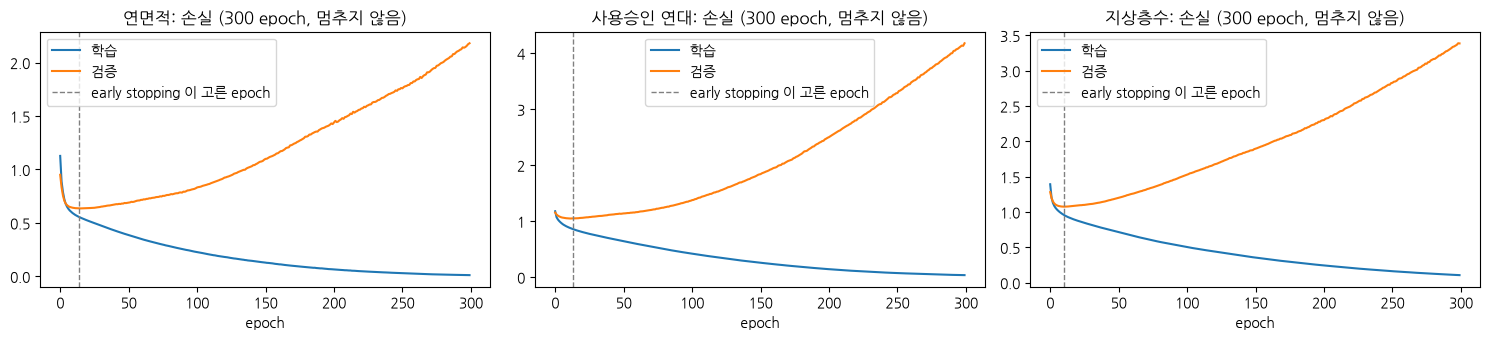

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
for a, (t, T) in zip(ax, TARGETS.items()):
    h = LONG[t].history
    a.plot(h['loss'], label='학습'); a.plot(h['val_loss'], label='검증')
    a.axvline(BEST[t] - 1, color='gray', ls='--', lw=1, label='early stopping 이 고른 epoch')
    a.set_title(f"{T['name']}: 손실 (300 epoch, 멈추지 않음)"); a.set_xlabel('epoch'); a.legend()
plt.tight_layout(); plt.show()

## 8. 은닉층 실험
대상마다 구조를 바꿔 시드 3개(42, 43, 44)로 학습하고 평균을 본다. 모두 같은 early stopping. 구조는 **검증 정확도**로 고르는 것이 원칙이라 검증·테스트를 함께 적는다.

In [14]:
HIDDEN = [(16,), (64,), (64, 32), (128, 64)]
rows = []
for t, T in TARGETS.items():
    s = S[t]
    for hidden in HIDDEN:
        va, ta = [], []
        for k in range(3):
            m = build(s['n'], hidden, seed=SEED + k)
            h = fit(s, m)
            va.append(h.history['val_accuracy'][int(np.argmin(h.history['val_loss']))])
            ta.append(accuracy_score(s['y_te'], m.predict(s['X_te'], verbose=0).argmax(1)))
        rows.append({'대상': T['name'], '은닉층': str(hidden), '검증 정확도 평균': np.mean(va), '테스트 정확도 평균': np.mean(ta),
                     '테스트 최저': min(ta), '테스트 최고': max(ta)})
EXP = pd.DataFrame(rows).set_index(['대상', '은닉층'])
EXP.round(3)

E0000 00:00:1795393856.669942    2518 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1795393865.246948    2518 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1795393874.727589    2518 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1795393882.914565    2518 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1795393887.961813    2518 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


E0000 00:00:1795393894.878272    2518 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


... (14 outputs left out)

E0000 00:00:1795394000.296616    2518 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1795394006.581602    2518 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1795394013.385153    2518 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


검증 정확도 평균  테스트 정확도 평균  테스트 최저  테스트 최고
대상      은닉층                                             
연면적     (16,)          0.740       0.696   0.681   0.709
        (64,)          0.751       0.693   0.683   0.702
        (64, 32)       0.760       0.705   0.693   0.714
        (128, 64)      0.757       0.698   0.690   0.702
사용승인 연대 (16,)          0.559       0.558   0.550   0.564
        (64,)          0.546       0.560   0.552   0.573
        (64, 32)       0.554       0.559   0.552   0.573
        (128, 64)      0.554       0.568   0.559   0.575
지상층수    (16,)          0.565       0.546   0.545   0.547
        (64,)          0.564       0.540   0.536   0.545
        (64, 32)       0.576       0.557   0.557   0.557
        (128, 64)      0.586       0.555   0.552   0.559

In [15]:
lines = []
for t, T in TARGETS.items():
    e = EXP.loc[T['name']]
    best = e['검증 정확도 평균'].idxmax()
    gap = e.loc[best, '검증 정확도 평균'] - e.loc['(64, 32)', '검증 정확도 평균']
    spread = (e['테스트 최고'] - e['테스트 최저']).mean()
    verdict = ('64-32 가 검증 정확도도 가장 높다' if best == '(64, 32)' else
               f'차이({gap:.3f})가 시드만 바꿔도 생기는 흔들림({spread:.3f})보다 작거나 비슷해 64-32 를 그대로 쓴다' if gap <= spread else
               f'차이({gap:.3f})가 시드 흔들림({spread:.3f})보다 크다. 세 대상을 같은 구조로 비교하려고 화면 모델은 64-32 로 두지만, 이 대상은 {best} 가 더 나을 수 있다')
    lines.append(f"- **{T['name']}**: 검증 정확도가 가장 높은 구조는 {best} ({e.loc[best, '검증 정확도 평균']:.3f}), "
                 f"64-32 는 {e.loc['(64, 32)', '검증 정확도 평균']:.3f}. {verdict}.")
EXP_NOTE = '\n'.join(lines)
display(Markdown('**읽는 법**\n\n' + EXP_NOTE))

**읽는 법**

- **연면적**: 검증 정확도가 가장 높은 구조는 (64, 32) (0.760), 64-32 는 0.760. 64-32 가 검증 정확도도 가장 높다.
- **사용승인 연대**: 검증 정확도가 가장 높은 구조는 (16,) (0.559), 64-32 는 0.554. 차이(0.005)가 시드만 바꿔도 생기는 흔들림(0.018)보다 작거나 비슷해 64-32 를 그대로 쓴다.
- **지상층수**: 검증 정확도가 가장 높은 구조는 (128, 64) (0.586), 64-32 는 0.576. 차이(0.011)가 시드 흔들림(0.005)보다 크다. 세 대상을 같은 구조로 비교하려고 화면 모델은 64-32 로 두지만, 이 대상은 (128, 64) 가 더 나을 수 있다.

## 9. 오답 분석
### 9-1. 혼동행렬 (신경망, 테스트)

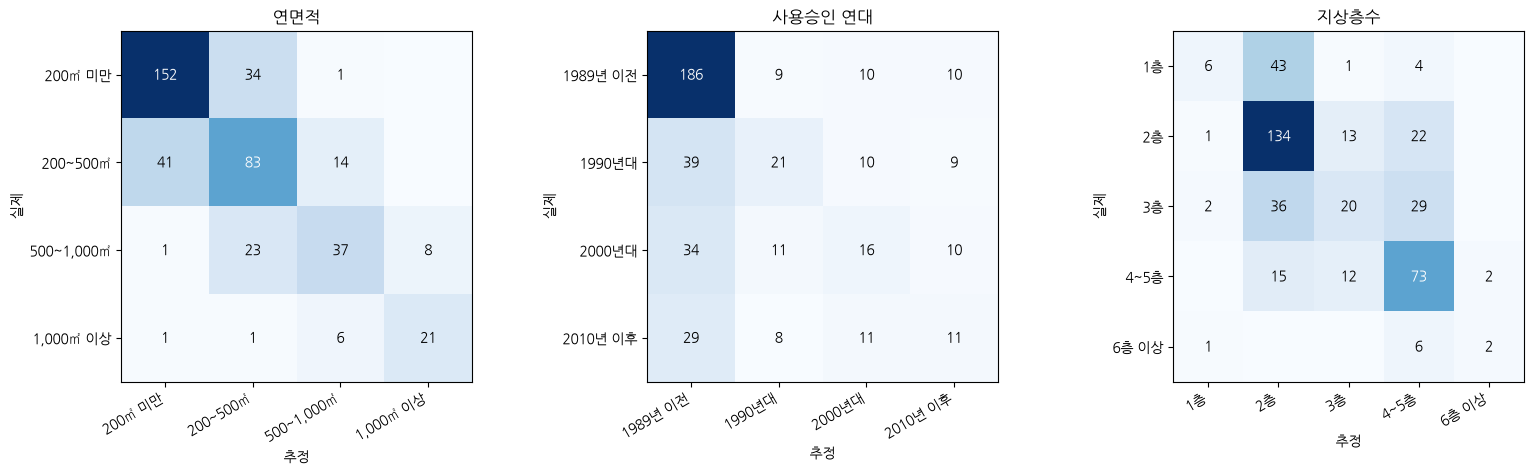

,오답,한 구간 차이,두 구간 이상
연면적,130,126,4
사용승인 연대,190,90,100
지상층수,187,142,45


In [16]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
ADJ = {}
for a, (t, T) in zip(ax, TARGETS.items()):
    s = S[t]; n = s['n']
    cm = confusion_matrix(s['y_te'], s['p_nn'], labels=range(n))
    a.imshow(cm, cmap='Blues')
    a.set_xticks(range(n)); a.set_yticks(range(n))
    a.set_xticklabels(T['labels'], rotation=30, ha='right'); a.set_yticklabels(T['labels'])
    for i in range(n):
        for j in range(n):
            if cm[i, j]: a.text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else 'black')
    a.set_xlabel('추정'); a.set_ylabel('실제'); a.set_title(T['name'])
    err = np.abs(s['y_te'] - s['p_nn'])
    ADJ[t] = {'오답': int((err > 0).sum()), '한 구간 차이': int((err == 1).sum()), '두 구간 이상': int((err >= 2).sum())}
plt.tight_layout(); plt.show()
pd.DataFrame({T['name']: ADJ[t] for t, T in TARGETS.items()}).T

### 9-2. 어떤 구간을 틀리나, 그리고 추정할 건물은 학습한 건물과 비슷한가
실제 구간별 정답률을 보고, 학습에 쓴 건물(값 있음)과 추정할 건물(값 없음)의 바닥 모양을 비교한다. 두 무리가 많이 다르면 테스트 정확도가 빈칸 건물에서 그대로 나온다고 볼 수 없다.

In [17]:
rows = []
for t, T in TARGETS.items():
    s = S[t]
    for k, lab in enumerate(T['labels']):
        mk = s['y_te'] == k
        rows.append({'대상': T['name'], '실제 구간': lab, '테스트 동수': int(mk.sum()),
                     '정답률': float((s['p_nn'][mk] == k).mean()) if mk.any() else np.nan})
PER = pd.DataFrame(rows).set_index(['대상', '실제 구간'])
display(PER.round(3))

rows = []
for t, T in TARGETS.items():
    for g, mk in [('학습에 쓴 건물 (값 있음)', HAS[t]), ('추정할 건물 (값 없음)', B['miss_' + t].to_numpy())]:
        X = B[mk]
        rows.append({'대상': T['name'], '무리': g, '동수': int(mk.sum()), '바닥면적 중앙값(㎡)': X['area'].median(),
                     '바닥면적 50㎡ 미만 비율': (X['area'] < 50).mean(), '모양 compact 중앙값': X['compact'].median(),
                     '반경 50m 건물 수 중앙값': X['n_50m'].median()})
SHIFT = pd.DataFrame(rows).set_index(['대상', '무리'])
SHIFT.round(3)

테스트 동수    정답률
대상      실제 구간                    
연면적     200㎡ 미만        187  0.813
        200~500㎡       138  0.601
        500~1,000㎡      69  0.536
        1,000㎡ 이상       29  0.724
사용승인 연대 1989년 이전       215  0.865
        1990년대          79  0.266
        2000년대          71  0.225
        2010년 이후        59  0.186
지상층수    1층              54  0.111
        2층             170  0.788
        3층              87  0.230
        4~5층           102  0.716
        6층 이상            9  0.222

동수  바닥면적 중앙값(㎡)  바닥면적 50㎡ 미만 비율  모양 compact 중앙값  \
대상      무리                                                                   
연면적     학습에 쓴 건물 (값 있음)  2112      123.226           0.029           0.706   
        추정할 건물 (값 없음)     336       25.932           0.637           0.694   
사용승인 연대 학습에 쓴 건물 (값 있음)  2118      123.209           0.031           0.706   
        추정할 건물 (값 없음)     330       25.482           0.636           0.696   
지상층수    학습에 쓴 건물 (값 있음)  2108      123.291           0.027           0.706   
        추정할 건물 (값 없음)     340       25.235           0.647           0.695   

                         반경 50m 건물 수 중앙값  
대상      무리                                
연면적     학습에 쓴 건물 (값 있음)             24.0  
        추정할 건물 (값 없음)               20.0  
사용승인 연대 학습에 쓴 건물 (값 있음)             24.0  
        추정할 건물 (값 없음)               20.0  
지상층수    학습에 쓴 건물 (값 있음)             24.0  
        추정할 건물 (값 없음)               20.0

In [18]:
lines = []
for t, T in TARGETS.items():
    r = RES[t]; nn = r['신경망 Dense 64-32']['정확도']
    base = max((k for k in r if not k.startswith('신경망')), key=lambda k: r[k]['정확도'])
    a = ADJ[t]; p = PER.loc[T['name']].dropna()
    sh = SHIFT.loc[T['name']]
    m_tr, m_ms = sh['바닥면적 중앙값(㎡)'].iloc[0], sh['바닥면적 중앙값(㎡)'].iloc[1]
    lines.append(
        f"- **{T['name']}**: 신경망 정확도 {nn:.3f}, 가장 좋은 기준선({base}) {r[base]['정확도']:.3f} (차이 {nn - r[base]['정확도']:+.3f}). "
        f"오답 {a['오답']}동 중 {a['한 구간 차이']}동({100 * a['한 구간 차이'] / max(a['오답'], 1):.0f}%)이 바로 옆 구간. "
        f"정답률이 가장 낮은 구간은 {p['정답률'].idxmin()} ({p['정답률'].min():.3f}, 테스트 {int(p.loc[p['정답률'].idxmin(), '테스트 동수'])}동). "
        f"추정할 건물의 바닥면적 중앙값은 {m_ms:.0f}㎡로 학습 건물({m_tr:.0f}㎡)의 {m_ms / m_tr:.2f}배다.")
ERR_NOTE = '\n'.join(lines)
display(Markdown('**읽는 법**\n\n' + ERR_NOTE + '\n\n'
                 '빈칸 건물은 건축물대장과 연결되지 않은 작은 부속 건물·창고 등이 많아 학습 건물과 성격이 다르다. '
                 '모델은 이런 건물을 거의 본 적이 없으므로, 테스트 정확도는 빈칸 건물에서의 정확도를 보장하지 않는다. 그래서 화면에서는 참고용으로만 쓴다.'))

**읽는 법**

- **연면적**: 신경망 정확도 0.693, 가장 좋은 기준선(로지스틱 회귀) 0.683 (차이 +0.009). 오답 130동 중 126동(97%)이 바로 옆 구간. 정답률이 가장 낮은 구간은 500~1,000㎡ (0.536, 테스트 69동). 추정할 건물의 바닥면적 중앙값은 26㎡로 학습 건물(123㎡)의 0.21배다.
- **사용승인 연대**: 신경망 정확도 0.552, 가장 좋은 기준선(이웃 8동 다수결) 0.578 (차이 -0.026). 오답 190동 중 90동(47%)이 바로 옆 구간. 정답률이 가장 낮은 구간은 2010년 이후 (0.186, 테스트 59동). 추정할 건물의 바닥면적 중앙값은 25㎡로 학습 건물(123㎡)의 0.21배다.
- **지상층수**: 신경망 정확도 0.557, 가장 좋은 기준선(로지스틱 회귀) 0.521 (차이 +0.036). 오답 187동 중 142동(76%)이 바로 옆 구간. 정답률이 가장 낮은 구간은 1층 (0.111, 테스트 54동). 추정할 건물의 바닥면적 중앙값은 25㎡로 학습 건물(123㎡)의 0.20배다.

빈칸 건물은 건축물대장과 연결되지 않은 작은 부속 건물·창고 등이 많아 학습 건물과 성격이 다르다. 모델은 이런 건물을 거의 본 적이 없으므로, 테스트 정확도는 빈칸 건물에서의 정확도를 보장하지 않는다. 그래서 화면에서는 참고용으로만 쓴다.

## 10. 결과표

In [19]:
def fmt_row(name, sc, bold=False):
    c = [f"{sc['정확도']:.3f}", f"{sc['macro F1']:.3f}", f"{sc['±1 구간 정확도']:.3f}"]
    if bold: name, c = f'**{name}**', [f'**{x}**' for x in c]
    return f"| {name} | " + ' | '.join(c) + ' |'

md = [f"아래 숫자는 이 노트북을 실행한 결과다 (SEED=42, op determinism, GitHub Actions 리눅스·파이썬 3.12·tensorflow-cpu). "
      f"건축물대장 표제부: {'없음 (브이월드 값만 사용)' if REG is None else f'있음, 채운 빈 칸 {REG_FILLED}, 대장 값으로 바꾼 칸 {REG_REPLACED}'}.", '',
      '| 대상 | 학습 | 테스트 | 추정할 건물 | 신경망 정확도 | 가장 좋은 기준선 | 차이 |', '|---|---|---|---|---|---|---|']
for t, T in TARGETS.items():
    r = RES[t]; nn = r['신경망 Dense 64-32']['정확도']
    base = max((k for k in r if not k.startswith('신경망')), key=lambda k: r[k]['정확도'])
    md.append(f"| {T['name']} ({len(T['labels'])}구간) | {SIZES.loc[T['name'], '학습']} | {SIZES.loc[T['name'], '테스트']} | "
              f"{SIZES.loc[T['name'], '추정할 건물(빈 값)']} | {nn:.3f} | {base} {r[base]['정확도']:.3f} | {nn - r[base]['정확도']:+.3f} |")
for t, T in TARGETS.items():
    md += ['', f"**{T['name']}** (테스트 {SIZES.loc[T['name'], '테스트']}동)", '', '| 방법 | 정확도 | macro F1 | ±1 구간 정확도 |', '|---|---|---|---|']
    for k, sc in RES[t].items():
        name = f"최빈 구간 (모두 {T['labels'][S[t]['mode']]})" if k == '최빈 구간' else \
               f"신경망 Dense 64-32 (early stopping {BEST[t]} epoch)" if k.startswith('신경망') else k
        md.append(fmt_row(name, sc, bold=k.startswith('신경망')))
    o = OVER.loc[T['name']]
    md.append('')
    md.append(f"과적합: early stopping 학습 {o.iloc[0]['학습 정확도']:.3f} / 테스트 {o.iloc[0]['테스트 정확도']:.3f} (차이 {o.iloc[0]['차이']:.3f}), "
              f"멈추지 않고 300 epoch 학습 {o.iloc[1]['학습 정확도']:.3f} / 테스트 {o.iloc[1]['테스트 정확도']:.3f} (차이 {o.iloc[1]['차이']:.3f}).")
md += ['', '**은닉층 실험**', '', EXP_NOTE, '', '**오답**', '', ERR_NOTE]
RESULT_MD = '\n'.join(md)
display(Markdown(RESULT_MD))

아래 숫자는 이 노트북을 실행한 결과다 (SEED=42, op determinism, GitHub Actions 리눅스·파이썬 3.12·tensorflow-cpu). 건축물대장 표제부: 없음 (브이월드 값만 사용).

| 대상 | 학습 | 테스트 | 추정할 건물 | 신경망 정확도 | 가장 좋은 기준선 | 차이 |
|---|---|---|---|---|---|---|
| 연면적 (4구간) | 1689 | 423 | 336 | 0.693 | 로지스틱 회귀 0.683 | +0.009 |
| 사용승인 연대 (4구간) | 1694 | 424 | 330 | 0.552 | 이웃 8동 다수결 0.578 | -0.026 |
| 지상층수 (5구간) | 1686 | 422 | 340 | 0.557 | 로지스틱 회귀 0.521 | +0.036 |

**연면적** (테스트 423동)

| 방법 | 정확도 | macro F1 | ±1 구간 정확도 |
|---|---|---|---|
| 최빈 구간 (모두 200㎡ 미만) | 0.442 | 0.153 | 0.768 |
| 이웃 8동 다수결 | 0.499 | 0.375 | 0.882 |
| 로지스틱 회귀 | 0.683 | 0.661 | 0.981 |
| **신경망 Dense 64-32 (early stopping 15 epoch)** | **0.693** | **0.674** | **0.991** |

과적합: early stopping 학습 0.781 / 테스트 0.693 (차이 0.088), 멈추지 않고 300 epoch 학습 0.959 / 테스트 0.676 (차이 0.282).

**사용승인 연대** (테스트 424동)

| 방법 | 정확도 | macro F1 | ±1 구간 정확도 |
|---|---|---|---|
| 최빈 구간 (모두 1989년 이전) | 0.507 | 0.168 | 0.693 |
| 이웃 8동 다수결 | 0.578 | 0.440 | 0.741 |
| 로지스틱 회귀 | 0.550 | 0.389 | 0.745 |
| **신경망 Dense 64-32 (early stopping 14 epoch)** | **0.552** | **0.390** | **0.764** |

과적합: early stopping 학습 0.642 / 테스트 0.552 (차이 0.090), 멈추지 않고 300 epoch 학습 0.901 / 테스트 0.521 (차이 0.380).

**지상층수** (테스트 422동)

| 방법 | 정확도 | macro F1 | ±1 구간 정확도 |
|---|---|---|---|
| 최빈 구간 (모두 2층) | 0.403 | 0.115 | 0.737 |
| 이웃 8동 다수결 | 0.488 | 0.377 | 0.796 |
| 로지스틱 회귀 | 0.521 | 0.384 | 0.872 |
| **신경망 Dense 64-32 (early stopping 11 epoch)** | **0.557** | **0.418** | **0.893** |

과적합: early stopping 학습 0.605 / 테스트 0.557 (차이 0.048), 멈추지 않고 300 epoch 학습 0.913 / 테스트 0.488 (차이 0.425).

**은닉층 실험**

- **연면적**: 검증 정확도가 가장 높은 구조는 (64, 32) (0.760), 64-32 는 0.760. 64-32 가 검증 정확도도 가장 높다.
- **사용승인 연대**: 검증 정확도가 가장 높은 구조는 (16,) (0.559), 64-32 는 0.554. 차이(0.005)가 시드만 바꿔도 생기는 흔들림(0.018)보다 작거나 비슷해 64-32 를 그대로 쓴다.
- **지상층수**: 검증 정확도가 가장 높은 구조는 (128, 64) (0.586), 64-32 는 0.576. 차이(0.011)가 시드 흔들림(0.005)보다 크다. 세 대상을 같은 구조로 비교하려고 화면 모델은 64-32 로 두지만, 이 대상은 (128, 64) 가 더 나을 수 있다.

**오답**

- **연면적**: 신경망 정확도 0.693, 가장 좋은 기준선(로지스틱 회귀) 0.683 (차이 +0.009). 오답 130동 중 126동(97%)이 바로 옆 구간. 정답률이 가장 낮은 구간은 500~1,000㎡ (0.536, 테스트 69동). 추정할 건물의 바닥면적 중앙값은 26㎡로 학습 건물(123㎡)의 0.21배다.
- **사용승인 연대**: 신경망 정확도 0.552, 가장 좋은 기준선(이웃 8동 다수결) 0.578 (차이 -0.026). 오답 190동 중 90동(47%)이 바로 옆 구간. 정답률이 가장 낮은 구간은 2010년 이후 (0.186, 테스트 59동). 추정할 건물의 바닥면적 중앙값은 25㎡로 학습 건물(123㎡)의 0.21배다.
- **지상층수**: 신경망 정확도 0.557, 가장 좋은 기준선(로지스틱 회귀) 0.521 (차이 +0.036). 오답 187동 중 142동(76%)이 바로 옆 구간. 정답률이 가장 낮은 구간은 1층 (0.111, 테스트 54동). 추정할 건물의 바닥면적 중앙값은 25㎡로 학습 건물(123㎡)의 0.20배다.

In [20]:
res_table()

정확도  macro F1  ±1 구간 정확도
연면적     최빈 구간            0.442     0.153      0.768
        이웃 8동 다수결        0.499     0.375      0.882
        로지스틱 회귀          0.683     0.661      0.981
        신경망 Dense 64-32  0.693     0.674      0.991
사용승인 연대 최빈 구간            0.507     0.168      0.693
        이웃 8동 다수결        0.578     0.440      0.741
        로지스틱 회귀          0.550     0.389      0.745
        신경망 Dense 64-32  0.552     0.390      0.764
지상층수    최빈 구간            0.403     0.115      0.737
        이웃 8동 다수결        0.488     0.377      0.796
        로지스틱 회귀          0.521     0.384      0.872
        신경망 Dense 64-32  0.557     0.418      0.893

## 11. 화면에 쓰이는 곳
6절의 신경망 3개(학습 데이터로 학습, 위에서 평가한 그 모델)로 **그 속성이 빈 건물에만** 구간을 추정해 `data/building_imputation_pred.csv` 로 저장한다.
열: `idx`, `pnu`, 그리고 대상마다 `est_<대상>_class`(구간 번호)·`est_<대상>`(구간 이름)·`est_<대상>_p`(가장 높은 확률)·`p_<대상>_<번호>`(구간별 확률). 대상은 `area`(연면적), `year`(사용승인 연대), `flr`(지상층수). 그 속성이 있는 건물은 칸을 비운다.

`collect/build_web_data.py` 가 이 파일을 읽어 **그 속성이 빈 건물에만** `est_area`·`est_area_p`, `est_year`·`est_year_p`, `est_flr`·`est_p` 를 붙이고, 지도 건물 카드에
"추정 연면적 | 200~500㎡ (신경망 추정 44%, 참고용 · 판정에 쓰지 않음)" 처럼 보여 준다. **판정(대상·경계선·비대상·판정불가)은 실제 값만 쓰므로 바뀌지 않는다.**

같은 모델을 `web/data/models/building_imputation_area.json`, `_year.json`, `_flr.json` 으로도 내보낸다 (서버 `server/lib/nn.js` 가 TensorFlow 없이 계산, `node server/test/nn.js` 가 파일마다 예시 5개로 Keras 와 같은지 확인).

In [21]:
M = B.loc[B[['miss_' + t for t in TARGETS]].any(axis=1), ['idx', 'pnu']].copy()
rows = []
for t, T in TARGETS.items():
    mk = B['miss_' + t].to_numpy()
    prob = MODELS[t].predict(S[t]['sc'].transform(B.loc[mk, FEATS]).astype('float32'), verbose=0)
    ix = B.index[mk]
    cls = prob.argmax(1)
    M[f'est_{t}_class'] = pd.Series(cls, index=ix).astype('Int64')
    M[f'est_{t}'] = pd.Series(np.array(T['labels'])[cls], index=ix)
    M[f'est_{t}_p'] = pd.Series(prob.max(1).round(3), index=ix)
    for k in range(len(T['labels'])):
        M[f'p_{t}_{k}'] = pd.Series(prob[:, k].round(3), index=ix)
    cnt = pd.Series(np.array(T['labels'])[cls]).value_counts().reindex(T['labels'], fill_value=0)
    rows.append({'대상': T['name'], '추정한 건물': int(mk.sum()), '확률 0.5 미만': int((prob.max(1) < 0.5).sum()),
                 **{f'{k + 1}. {lab}': int(cnt[lab]) for k, lab in enumerate(T['labels'])}})
OUT_DIR = '../data' if os.path.isdir('../data') else '.'
M.to_csv(os.path.join(OUT_DIR, 'building_imputation_pred.csv'), index=False, encoding='utf-8-sig')
print('추정이 하나라도 있는 건물', len(M), '동 →', os.path.join(OUT_DIR, 'building_imputation_pred.csv'))
EST_SUMMARY = pd.DataFrame(rows).set_index('대상').fillna(0).astype(int)
EST_SUMMARY

추정이 하나라도 있는 건물 348 동 → ../data/building_imputation_pred.csv


,추정한 건물,확률 0.5 미만,1. 200㎡ 미만,2. 200~500㎡,"3. 500~1,000㎡","4. 1,000㎡ 이상",1. 1989년 이전,2. 1990년대,3. 2000년대,4. 2010년 이후,1. 1층,2. 2층,3. 3층,4. 4~5층,5. 6층 이상
대상,,,,,,,,,,,,,,,
연면적,336,7,270,43,13,10,0,0,0,0,0,0,0,0,0
사용승인 연대,330,51,0,0,0,0,289,9,20,12,0,0,0,0,0
지상층수,340,122,0,0,0,0,0,0,0,0,171,106,22,35,6


In [22]:
def b64(a):
    return base64.b64encode(np.asarray(a, dtype='<f4').tobytes()).decode('ascii')

MODEL_DIR = '../web/data/models' if os.path.isdir('../web/data') else '.'
os.makedirs(MODEL_DIR, exist_ok=True)
for t, T in TARGETS.items():
    m, s = MODELS[t], S[t]
    layers = []
    for L in m.layers:
        W, b = L.get_weights()
        layers.append({'units': int(W.shape[1]), 'activation': L.get_config()['activation'], 'W': b64(W), 'b': [float(x) for x in b]})
    ex = B[B['miss_' + t]].head(5)
    check = [{'input': {k: float(r[k]) for k in FEATS}, 'output': [float(x) for x in p]}
             for (_, r), p in zip(ex.iterrows(), m.predict(s['sc'].transform(ex[FEATS]).astype('float32'), verbose=0))]
    spec = {
        'name': f'building_imputation_{t}',
        'note': f"{T['name']} 구간 추정 (참고용, 판정에 쓰지 않음). 대상 속성 {T['attr']} 이 빈 건물에만 쓴다. 특징은 notebooks/building_imputation.ipynb 3절",
        'target': T['attr'],
        'input': {'type': 'dense', 'features': FEATS, 'mean': [float(x) for x in s['sc'].mean_], 'scale': [float(x) for x in s['sc'].scale_]},
        'layers': layers,
        'labels': T['labels'],
        'metrics': {k: {mm: round(float(v), 3) for mm, v in sc.items()} for k, sc in RES[t].items()},
        'check': check,
    }
    path = os.path.join(MODEL_DIR, f'building_imputation_{t}.json')
    with open(path, 'w', encoding='utf-8') as f:
        json.dump(spec, f, ensure_ascii=False)
    print('모델 저장', path)
old = os.path.join(MODEL_DIR, 'building_imputation.json')   # 예전 이름 (지상층수만 추정하던 모델)
if os.path.exists(old):
    os.remove(old); print('예전 모델 파일 지움', old)

모델 저장 ../web/data/models/building_imputation_area.json
모델 저장 ../web/data/models/building_imputation_year.json
모델 저장 ../web/data/models/building_imputation_flr.json
예전 모델 파일 지움 ../web/data/models/building_imputation.json
